# Telco Customer Churn Prediction using Random Forest
This notebook implements a complete Machine Learning workflow to predict customer churn based on the user-provided dataset. The project is divided into four distinct phases as required:
1. **Phase I:** Exploratory Data Analysis (EDA)
2. **Phase II:** Data Preprocessing
3. **Phase III:** Model Development
4. **Phase IV:** Model Evaluation and Visualizations

In [3]:
# In-line environment setup and dynamic installation of required packages
!pip install -q numpy pandas matplotlib seaborn scikit-learn

## Phase I: Exploratory Data Analysis (EDA)
In this initial phase, we import the core data science frameworks, load the data from your specific attached file, inspect its structure, target class distribution, and look at linear correlation interactions.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load your specific provided dataset
df = pd.read_csv('/content/Telco-Customer-Churn.csv')

# Basic structure exploration
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())
print("\nData Types & Info:")
df.info()

Dataset Shape: (7043, 21)

First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Data Types & Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043

Target Variable (Churn) Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


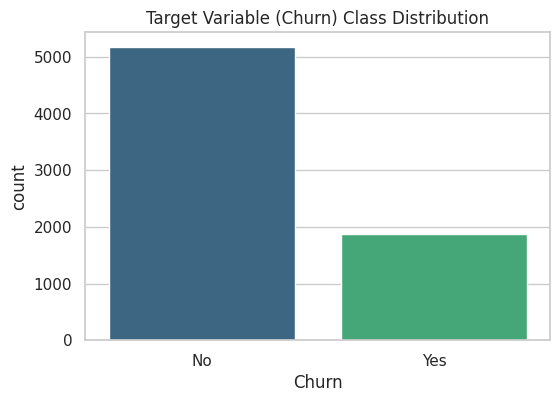

In [5]:
# Check target class distribution (Churn Imbalance map)
churn_counts = df['Churn'].value_counts()
print("Target Variable (Churn) Distribution:")
print(churn_counts)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', hue='Churn', palette='viridis', legend=False)
plt.title('Target Variable (Churn) Class Distribution')
plt.show()

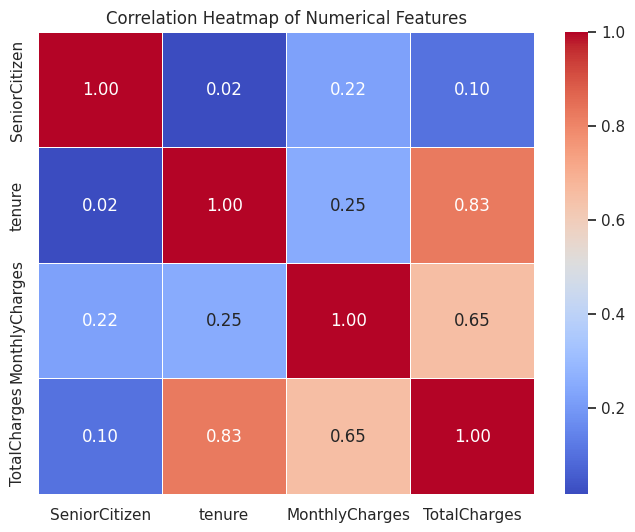

In [6]:
# Correlation Heatmap for Existing Numerical Features
# First convert any hidden object columns that should be numerical if needed
temp_df = df.copy()
temp_df['TotalCharges'] = pd.to_numeric(temp_df['TotalCharges'].astype(str).str.strip(), errors='coerce')
numerical_cols = temp_df.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(8, 6))
sns.heatmap(temp_df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

## Phase II: Preprocessing
This stage prepares the text categorical spaces and handles type coercion anomalies to clean vectors before training.

In [7]:
# 1. Clean TotalCharges (handle blank spaces/missing entries)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce')

# Impute missing records with the column median
if df['TotalCharges'].isnull().sum() > 0:
    median_val = df['TotalCharges'].median()
    df['TotalCharges'] = df['TotalCharges'].fillna(median_val)
    print(f"Imputed missing TotalCharges with median: {median_val}")

# Drop unique identifiers like customerID as they lack generalized predictive capacity
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn'].map({'Yes': 1, 'No': 0}) # Encode target to binaries

Imputed missing TotalCharges with median: 1397.475


In [8]:
# 2. Process categorical labels using One-Hot Encoding
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print(f"Feature matrix expanded from {X.shape[1]} to {X_encoded.shape[1]} columns after encoding.")

Feature matrix expanded from 19 to 30 columns after encoding.


In [9]:
from sklearn.model_selection import train_test_split

# 3. Strategic 80:20 data splitting with stratification to preserve label ratios
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set vectors shape: {X_train.shape}")
print(f"Testing set vectors shape: {X_test.shape}")

Training set vectors shape: (5634, 30)
Testing set vectors shape: (1409, 30)


### Architectural Implementation Note: Why Feature Scaling is Skipped
Tree-based machine learning architectures (such as Decision Trees and Random Forests) are inherently **scale-invariant**. They branch node rules by finding splitting thresholds based on feature criteria orderings rather than linear coordinate metrics. Scaling inputs across standard variations (`StandardScaler` or `MinMaxScaler`) changes the absolute space but completely preserves the ordinal relationship. Hence, scaling has no impact on tree routing topologies and is safely omitted here to prevent unnecessary compute overhead.

## Phase III: Model Development
We now fit a professional `RandomForestClassifier` ensemble while explicitly tuning hyperparameters to balance bias-variance trade-offs.

In [10]:
from sklearn.ensemble import RandomForestClassifier

# Instantiating Random Forest Ensemble
# - n_estimators=100: Stabilizes variance across independent bootstrapped trees.
# - max_depth=6: Regularizes individual decision depth to avoid overfitting noise.
# - class_weight='balanced': Compensates for structural class imbalance natively.
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    class_weight='balanced',
    random_state=42
)

# Fit model to training features
rf_model.fit(X_train, y_train)
print("Random Forest ensemble successfully trained.")

Random Forest ensemble successfully trained.


## Phase IV: Required Evaluation Metrics and Plotting
We evaluate performance across unseen testing records, plotting predictive validation visuals.

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# Generate testing predictions
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Display statistical Precision/Recall breakdown
print("Classification Report Summary:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

Classification Report Summary:
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



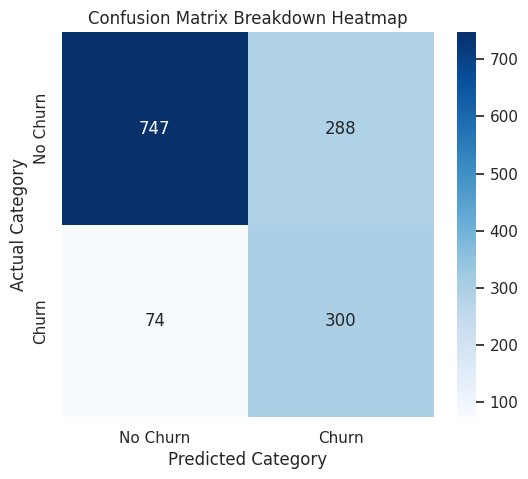

In [12]:
# 1. Confusion Matrix Heatmap Visual
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.title('Confusion Matrix Breakdown Heatmap')
plt.show()

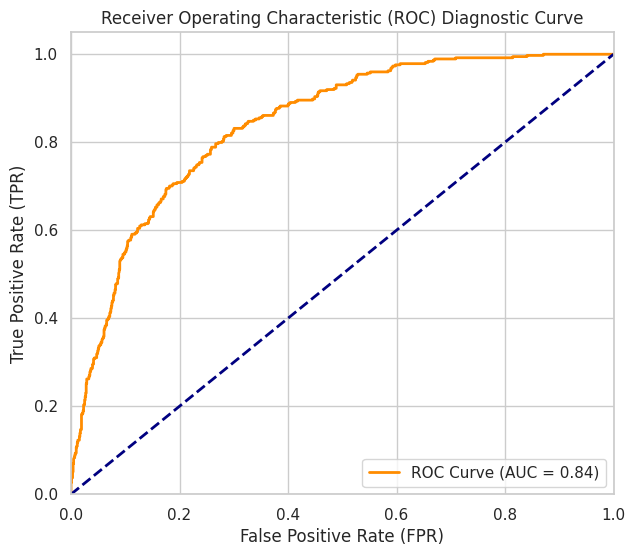

In [13]:
# 2. Continuous ROC-AUC Diagnostic Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Diagnostic Curve')
plt.legend(loc="lower right")
plt.show()

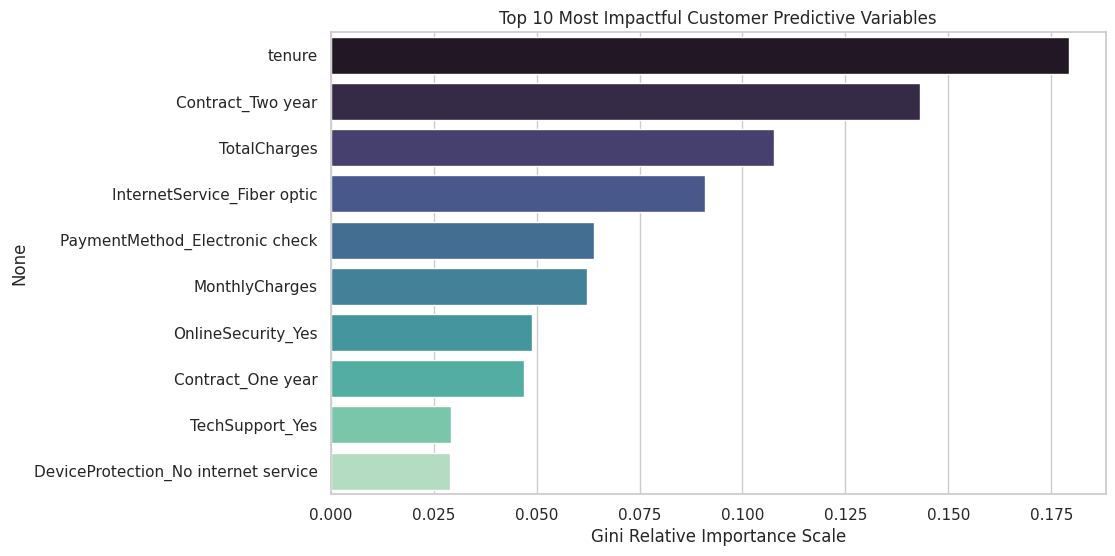

In [14]:
# 3. Top Predictive Feature Importance Bar Chart
importances = rf_model.feature_importances_
feature_names = X_encoded.columns
indices = np.argsort(importances)[::-1]

# Select the top 10 most impactful variables
top_n = 10
plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices[:top_n]], y=feature_names[indices[:top_n]], hue=feature_names[indices[:top_n]], palette='mako', legend=False)
plt.xlabel('Gini Relative Importance Scale')
plt.title('Top 10 Most Impactful Customer Predictive Variables')
plt.show()